# 16 — Day-30 Text Features from Activity Descriptions (NLP)

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

Hank Butler's third recommendation was: *"Process NLP Data: Explore and process text descriptions to generate new
features for model input."*

Every event has an English description (`activityNameEN`). This notebook tests whether **words in the descriptions
recorded by day 30** add predictive information to the best model from notebook 14. Two approaches are compared with the
same Logistic Regression:

- **C. Combined (notebook 14):** 7 counts + 15 activity indicators + activity-group indicators + progress feature.
- **E. Text:** the same C features **plus 30 TF-IDF text features**.

Everything else is unchanged: historically completed cases, the recorded activity span, the 63-day threshold, day-30
eligibility (a retrospective rule), the random split (677 / 161) and the temporal split (617 / 168), and
`StandardScaler` + `LogisticRegression(max_iter=1000)` without tuning.

## 2. Load the Data and Build the Day-30 Cohort

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)
case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data["long_case"] = (case_data["duration_days"] > 63).astype(int)

case_data["prediction_time"] = case_data["first_event"] + pd.Timedelta(days=30)
active = case_data[case_data["last_event"] > case_data["prediction_time"]]

print("Completed cases:", len(case_data))
print("Day-30 eligible cases:", len(active))

Completed cases: 956
Day-30 eligible cases: 838


## 3. The Text Data

`activityNameEN` is the English description of each event's activity code (`concept:name`). First, its quality in the
whole log:

In [3]:
descriptions = df["activityNameEN"]
print("Events:", len(df))
print("Missing descriptions:", descriptions.isna().sum())
print("Empty descriptions:", (descriptions.str.strip() == "").sum())
print("Distinct descriptions:", descriptions.nunique())
print("Distinct activity codes:", df["concept:name"].nunique())

Events: 52217
Missing descriptions: 0
Empty descriptions: 0
Distinct descriptions: 289
Distinct activity codes: 398


**Do descriptions match activity codes?** If every code always had the same description, the two would carry the same
information. I count codes with more than one description, and descriptions used by more than one code.

In [4]:
names_per_code = df.groupby("concept:name")["activityNameEN"].nunique()
codes_per_name = df.groupby("activityNameEN")["concept:name"].nunique()

print("Activity codes with exactly one description:", (names_per_code == 1).sum(), "of", len(names_per_code))
print("Activity codes with more than one description:", (names_per_code > 1).sum())
print("Descriptions shared by more than one code:", (codes_per_name > 1).sum(), "of", len(codes_per_name))

Activity codes with exactly one description: 377 of 398
Activity codes with more than one description: 21
Descriptions shared by more than one code: 91 of 289


## 4. Shared Helpers (Copied Unchanged from Notebook 14)

These cells are exactly the code of notebook 14, so approach C is rebuilt in the same way.

In [5]:
def add_activity_groups(events):
    # the group is the prefix of the activity code, e.g. "02_DRZ" from "02_DRZ_010"
    events = events.copy()
    events["activity_group"] = events["concept:name"].str.extract(r"^(\d{2}_[A-Z0-9]+)_")[0]

    # for the main process 01_HOOFD, add the first digit of the number: "01_HOOFD_065_1" -> "01_HOOFD_0xx"
    is_main = events["activity_group"] == "01_HOOFD"
    first_digit = events.loc[is_main, "concept:name"].str[9]   # "01_HOOFD_" has 9 characters
    events.loc[is_main, "activity_group"] = "01_HOOFD_" + first_digit + "xx"
    return events


grouped_log = add_activity_groups(df)
print("Activity codes:", grouped_log["concept:name"].nunique())
print("Activity groups:", grouped_log["activity_group"].nunique())
print("Events without a group:", grouped_log["activity_group"].isna().sum())

Activity codes: 398
Activity groups: 28
Events without a group: 0


**Keep only the events up to each case's day-30 cutoff.**

In [6]:
def events_by_day30(event_table, cases):
    # keep only events of the given cases that happened on or before that case's day-30 cutoff
    events = event_table[event_table["case:concept:name"].isin(cases.index)].copy()
    events["prediction_time"] = events["case:concept:name"].map(cases["prediction_time"])
    events["first_event"] = events["case:concept:name"].map(cases["first_event"])
    first30 = events[events["time:timestamp"] <= events["prediction_time"]].copy()
    first30["day"] = (first30["time:timestamp"] - first30["first_event"]).dt.total_seconds() / (24 * 60 * 60)
    return first30

**The seven count features** (two of them are exact combinations of others, kept for continuity).

In [7]:
count_columns = [
    "events_first30",
    "unique_activities_first30",
    "unique_resources_first30",
    "repeated_activities_first30",
    "events_first15",
    "events_days16_30",
    "days_since_last_event",
]


def count_features(first30, cases):
    first30 = first30.copy()
    first30["in_first15"] = first30["day"] <= 15
    features = first30.groupby("case:concept:name").agg(
        events_first30=("concept:name", "size"),
        unique_activities_first30=("concept:name", "nunique"),
        unique_resources_first30=("org:resource", "nunique"),
        events_first15=("in_first15", "sum"),
        last_event_by_day30=("time:timestamp", "max"),
    )
    features["repeated_activities_first30"] = features["events_first30"] - features["unique_activities_first30"]
    features["events_days16_30"] = features["events_first30"] - features["events_first15"]
    features["days_since_last_event"] = (
        cases.loc[features.index, "prediction_time"] - features["last_event_by_day30"]
    ).dt.total_seconds() / (24 * 60 * 60)
    return features[count_columns]

**Apply the helpers** to all eligible cases and check that no event after the cutoff was used.

In [8]:
first30 = add_activity_groups(events_by_day30(df, active))
counts = count_features(first30, active)
y = active.loc[counts.index, "long_case"]

print("Events recorded by day 30:", len(first30))
print("Latest event used, in days after the case start:", first30["day"].max())
print("Every event used is on or before its case's cutoff:", (first30["time:timestamp"] <= first30["prediction_time"]).all())
print("Activity groups recorded by day 30:", first30["activity_group"].nunique())

Events recorded by day 30: 14551
Latest event used, in days after the case start: 30.0
Every event used is on or before its case's cutoff: True
Activity groups recorded by day 30: 23


**The 15 original activity indicators** (selected on training cases only).

In [9]:
def select_activities(first30, case_ids):
    # activity codes recorded in 10-90% of the given cases, at most 15, most frequent first (ties by code)
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("concept:name")["case:concept:name"].nunique() / len(case_ids) * 100
    share = share.rename("train_cases_pct").reset_index()
    share = share[(share["train_cases_pct"] >= 10) & (share["train_cases_pct"] <= 90)]
    share = share.sort_values(["train_cases_pct", "concept:name"], ascending=[False, True])
    return share.head(15)["concept:name"].tolist()


def activity_flags(first30, activities, case_ids):
    # 1 if the activity was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for activity in activities:
        cases_with_activity = first30.loc[first30["concept:name"] == activity, "case:concept:name"].unique()
        flags["act_" + activity] = flags.index.isin(cases_with_activity).astype(int)
    return flags

**The group indicators and the progress feature** from notebook 14 (selected on training cases only).

In [10]:
def select_groups(first30, case_ids):
    # activity groups recorded by day 30 in at least 5% of the given cases, except 01_HOOFD_0xx
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("activity_group")["case:concept:name"].nunique() / len(case_ids) * 100
    groups = share[share >= 5].index.tolist()
    groups.remove("01_HOOFD_0xx")
    return sorted(groups)

In [11]:
def group_flags(first30, groups, case_ids):
    # 1 if the group was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for group in groups:
        cases_with_group = first30.loc[first30["activity_group"] == group, "case:concept:name"].unique()
        flags["grp_" + group] = flags.index.isin(cases_with_group).astype(int)

    # every rare group (not selected and not 01_HOOFD_0xx) goes into one column
    rare_events = first30[~first30["activity_group"].isin(groups + ["01_HOOFD_0xx"])]
    flags["grp_other_group"] = flags.index.isin(rare_events["case:concept:name"].unique()).astype(int)
    return flags

In [12]:
def highest_main_stage(first30, case_ids):
    # highest first digit of a 01_HOOFD code recorded by day 30, e.g. 4 for "01_HOOFD_4xx"
    main_events = first30[first30["activity_group"].str.startswith("01_HOOFD_")]
    stages = main_events["activity_group"].str[9].astype(int)
    highest = stages.groupby(main_events["case:concept:name"]).max()
    return highest.reindex(case_ids).fillna(0).astype(int).rename("highest_main_stage")

**Feature table for C**, and the same model and scores as notebook 14.

In [13]:
def make_X(case_ids, approach, activities, groups):
    X = counts.loc[case_ids]
    if approach in ["A. Original", "C. Combined"]:
        X = X.join(activity_flags(first30, activities, case_ids))
    if approach in ["B. Grouped", "C. Combined"]:
        X = X.join(group_flags(first30, groups, case_ids))
        X = X.join(highest_main_stage(first30, case_ids))
    return X

In [14]:
def fit_logistic_regression(X_train, y_train):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)


def score(model, X, y_true):
    predictions = model.predict(X)
    return {
        "ROC-AUC": roc_auc_score(y_true, model.predict_proba(X)[:, 1]),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions),
        "Cases flagged long": int(predictions.sum()),
    }

## 5. Descriptions Available by Day 30

Only the descriptions of events recorded by each case's day-30 cutoff are used (the `first30` table from above).

In [15]:
print("Events recorded by day 30:", len(first30))
print("Missing descriptions among them:", first30["activityNameEN"].isna().sum())
print("Distinct descriptions recorded by day 30:", first30["activityNameEN"].nunique())
print()
print("Most common descriptions by day 30:")
first30["activityNameEN"].value_counts().head(10)

Events recorded by day 30: 14551
Missing descriptions among them: 0
Distinct descriptions recorded by day 30: 163

Most common descriptions by day 30:


activityNameEN
send confirmation receipt                1378
register submission date request          832
phase application received                796
forward to the competent authority        746
enter senddate acknowledgement            730
regular procedure without MER             713
registration date publication             580
OLO messaging active                      539
enter senddate procedure confirmation     471
procedure change                          450
Name: count, dtype: int64

## 6. One Text Document per Case

For every case I join the English descriptions of its events recorded by day 30 into one text.

**Rule for repeated descriptions:** each distinct description is used **once per case**, even if the activity happened
several times. So the text says *which kinds of steps* happened by day 30, like the 0/1 activity indicators; how many
events happened is already measured by the count features.

In [16]:
def case_documents(first30, case_ids):
    # one text per case: every distinct English description recorded by day 30, joined with spaces
    events = first30[first30["case:concept:name"].isin(case_ids)]
    unique_descriptions = events[["case:concept:name", "activityNameEN"]].drop_duplicates()
    documents = unique_descriptions.groupby("case:concept:name")["activityNameEN"].agg(" ".join)
    return documents.reindex(case_ids, fill_value="")

In [17]:
example_documents = case_documents(first30, list(active.index[:2]))
for case, text in example_documents.items():
    print(case, "->", text[:300], "...")
    print()

10009138 -> register submission date request OLO messaging active send confirmation receipt forward to the competent authority regular procedure without MER create procedure confirmation create subcases completeness create publication document phase application received start WABOprocedure registration date pub ...

10051383 -> create procedure confirmation create subcases completeness create publication document OLO messaging active send confirmation receipt forward to the competent authority regular procedure without MER register submission date request start WABOprocedure phase application received registration date pub ...



## 7. TF-IDF in Simple Words

`TfidfVectorizer` turns each text into numbers, one column per word:

- **TF (term frequency):** how often a word appears in a case's text.
- **IDF (inverse document frequency):** words that appear in almost every case get a lower weight, and words that
  appear in fewer cases get a higher weight.
- The result is a value for every word and case: high if the word is in that case's text and is not used by every case.

Fixed settings, chosen before running anything and not tuned:

- `max_features=30`: keep only the 30 most frequent words;
- `min_df=3`: a word must appear in at least 3 training cases;
- `stop_words="english"`: leave out very common English words such as *the*, *to* and *of*.

The vectorizer is **fitted on training cases only**. Validation and test texts are only transformed, so a word that
appears only in them is simply ignored.

In [18]:
def text_features(train_ids, other_ids):
    vectorizer = TfidfVectorizer(max_features=30, min_df=3, stop_words="english")
    train_matrix = vectorizer.fit_transform(case_documents(first30, train_ids))   # training cases only
    other_matrix = vectorizer.transform(case_documents(first30, other_ids))

    column_names = ["txt_" + word for word in vectorizer.get_feature_names_out()]
    train_text = pd.DataFrame(train_matrix.toarray(), index=train_ids, columns=column_names)
    other_text = pd.DataFrame(other_matrix.toarray(), index=other_ids, columns=column_names)
    return train_text, other_text

**Feature table for E:** the C features plus the 30 text columns.

In [19]:
def make_X_text(train_ids, other_ids, activities, groups):
    train_text, other_text = text_features(train_ids, other_ids)
    X_train = make_X(train_ids, "C. Combined", activities, groups).join(train_text)
    X_other = make_X(other_ids, "C. Combined", activities, groups).join(other_text)
    return X_train, X_other

## 8. The Two Splits (Same as Notebooks 10–15)

In [20]:
day14_cases = case_data[case_data["last_event"] > case_data["first_event"] + pd.Timedelta(days=14)]
original_train_ids, original_test_ids = train_test_split(
    day14_cases.index, test_size=0.20, random_state=42, stratify=day14_cases["long_case"]
)

random_train_ids = [case for case in original_train_ids if case in active.index]
random_test_ids = [case for case in original_test_ids if case in active.index]

print("Random training cases:", len(random_train_ids), "| long:", y.loc[random_train_ids].sum())
print("Random test cases:", len(random_test_ids), "| long:", y.loc[random_test_ids].sum())
print("Overlap:", len(set(random_train_ids) & set(random_test_ids)))

Random training cases: 677 | long: 377
Random test cases: 161 | long: 95
Overlap: 0


In [21]:
sorted_cases = active.sort_values("prediction_time", kind="stable")
boundary = sorted_cases["prediction_time"].iloc[int(len(sorted_cases) * 0.8)]

temporal_test = sorted_cases[sorted_cases["prediction_time"] >= boundary]
candidates = sorted_cases[sorted_cases["prediction_time"] < boundary]
temporal_train = candidates[(candidates["last_event"] < boundary) & (candidates["end_date"] < boundary)]
temporal_train_ids, temporal_test_ids = temporal_train.index, temporal_test.index

print("Boundary:", boundary)
print("Temporal training cases:", len(temporal_train_ids), "| long:", y.loc[temporal_train_ids].sum())
print("Temporal test cases:", len(temporal_test_ids), "| long:", y.loc[temporal_test_ids].sum())
print("Overlap:", len(set(temporal_train_ids) & set(temporal_test_ids)))

Boundary: 2013-10-25 22:00:00+00:00
Temporal training cases: 617 | long: 328
Temporal test cases: 168 | long: 100
Overlap: 0


## 9. Are the Fixed TF-IDF Settings Valid Everywhere?

With `min_df=3` there must be at least 30 words that appear in 3 or more training cases; otherwise fewer than 30 features
would be created. I check every cross-validation training part and both final training groups.

In [22]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_index = pd.Index(random_train_ids)   # lets us turn fold positions into case IDs
fold_parts = list(folds.split(train_index, y.loc[train_index]))

training_groups = {"random training": train_index, "temporal training": temporal_train_ids}
for fold, (fit_positions, val_positions) in enumerate(fold_parts, start=1):
    training_groups[f"fold {fold} training part"] = train_index[fit_positions]

for name, ids in training_groups.items():
    vectorizer = TfidfVectorizer(max_features=30, min_df=3, stop_words="english")
    vectorizer.fit(case_documents(first30, ids))
    print(f"{name:<22} cases {len(ids)} | text features created: {len(vectorizer.get_feature_names_out())}")

random training        cases 677 | text features created: 30


temporal training      cases 617 | text features created: 30


fold 1 training part   cases 541 | text features created: 30
fold 2 training part   cases 541 | text features created: 30
fold 3 training part   cases 542 | text features created: 30


fold 4 training part   cases 542 | text features created: 30


fold 5 training part   cases 542 | text features created: 30


**The 30 words chosen on the random training cases**, with the share of those cases whose text contains each word:

In [23]:
random_words = TfidfVectorizer(max_features=30, min_df=3, stop_words="english")
random_matrix = random_words.fit_transform(case_documents(first30, random_train_ids))

contains_word = random_matrix.toarray() > 0          # True if the case's text contains the word
word_share = pd.Series(contains_word.mean(axis=0) * 100, index=random_words.get_feature_names_out())
word_share.sort_values(ascending=False).round(1)

date               99.4
request            99.4
register           99.3
submission         99.3
confirmation       97.3
phase              95.9
received           95.9
application        95.3
send               94.7
receipt            93.2
enter              92.5
senddate           92.3
procedure          90.5
competent          89.5
authority          89.5
forward            89.5
acknowledgement    87.7
regular            85.8
mer                85.8
olo                82.6
publication        72.8
registration       69.4
active             63.5
messaging          63.5
create             44.8
completeness       42.8
subcases           42.8
permit             28.5
decision           21.6
environmental      19.9
dtype: float64

## 10. Decision Rule (Fixed Before Looking at the Test Sets)

I prefer E over C only if E has a **higher mean cross-validation ROC-AUC**. The test sets are not used for the choice,
and the TF-IDF settings are not changed after seeing results.

## 11. Cross-Validation on the Random Training Cases

Same folds as notebooks 10–15. In every fold, the activities, the groups **and the TF-IDF vocabulary and weights** are
fitted on that fold's training part only.

In [24]:
cv_rows = []
for fold, (fit_positions, val_positions) in enumerate(fold_parts, start=1):
    fit_ids = train_index[fit_positions]
    val_ids = train_index[val_positions]
    y_fit, y_val = y.loc[fit_ids], y.loc[val_ids]

    baseline = DummyClassifier(strategy="most_frequent").fit(counts.loc[fit_ids], y_fit)
    cv_rows.append({"Fold": fold, "Approach": "Majority baseline", **score(baseline, counts.loc[val_ids], y_val)})

    activities = select_activities(first30, fit_ids)
    groups = select_groups(first30, fit_ids)

    model_c = fit_logistic_regression(make_X(fit_ids, "C. Combined", activities, groups), y_fit)
    cv_rows.append({"Fold": fold, "Approach": "C. Combined", **score(model_c, make_X(val_ids, "C. Combined", activities, groups), y_val)})

    X_fit, X_val = make_X_text(fit_ids, val_ids, activities, groups)
    model_e = fit_logistic_regression(X_fit, y_fit)
    cv_rows.append({"Fold": fold, "Approach": "E. Text", **score(model_e, X_val, y_val)})

cv_results = pd.DataFrame(cv_rows)

**Cross-validation results.** The standard deviation shows how much the five folds differ; it is not a confidence interval.

In [25]:
cv_results.groupby("Approach")[["ROC-AUC", "Precision", "Recall"]].agg(["mean", "std"]).round(3)

ROC-AUC        Precision        Recall       
                     mean    std      mean    std   mean    std
Approach                                                       
C. Combined         0.710  0.017     0.688  0.022  0.700  0.026
E. Text             0.702  0.033     0.672  0.033  0.685  0.045
Majority baseline   0.500  0.000     0.557  0.002  1.000  0.000

In [26]:
cv_results.pivot(index="Fold", columns="Approach", values="ROC-AUC").round(3)

Approach,C. Combined,E. Text,Majority baseline
Fold,,,
1,0.736,0.744,0.5
2,0.696,0.665,0.5
3,0.708,0.724,0.5
4,0.696,0.701,0.5
5,0.714,0.676,0.5


In [27]:
cv_roc = cv_results.groupby("Approach")["ROC-AUC"].mean()
preferred = "E. Text" if cv_roc["E. Text"] > cv_roc["C. Combined"] else "C. Combined"
print("Mean cross-validation ROC-AUC:", cv_roc.round(3).to_dict())
print("Preferred approach:", preferred)

Mean cross-validation ROC-AUC: {'C. Combined': 0.71, 'E. Text': 0.702, 'Majority baseline': 0.5}
Preferred approach: C. Combined


## 12. Random Test and Temporal Test

C and E are fitted once on each training group and scored once on its test cases. The TF-IDF vocabulary is fitted
separately on the random training cases and on the temporal training cases.

In [28]:
def evaluate_split(train_ids, test_ids):
    results = {}
    y_train, y_test = y.loc[train_ids], y.loc[test_ids]

    baseline = DummyClassifier(strategy="most_frequent").fit(counts.loc[train_ids], y_train)
    results["Majority baseline"] = score(baseline, counts.loc[test_ids], y_test)

    activities = select_activities(first30, train_ids)
    groups = select_groups(first30, train_ids)

    model_c = fit_logistic_regression(make_X(train_ids, "C. Combined", activities, groups), y_train)
    results["C. Combined"] = score(model_c, make_X(test_ids, "C. Combined", activities, groups), y_test)

    X_train, X_test = make_X_text(train_ids, test_ids, activities, groups)
    model_e = fit_logistic_regression(X_train, y_train)
    results["E. Text"] = score(model_e, X_test, y_test)
    return pd.DataFrame(results).T

In [29]:
random_results = evaluate_split(random_train_ids, random_test_ids)
temporal_results = evaluate_split(temporal_train_ids, temporal_test_ids)

## 13. Check: C Reproduces Notebook 14

Approach C uses the same code as notebook 14, so its results must match the outputs recorded there (rounded to 3 decimals).

In [30]:
recorded = {
    "cross-validation ROC-AUC": 0.710,
    "random test ROC-AUC": 0.708,
    "random test precision": 0.730,
    "random test recall": 0.768,
    "temporal test ROC-AUC": 0.705,
    "temporal test precision": 0.847,
    "temporal test recall": 0.500,
}
current = {
    "cross-validation ROC-AUC": cv_roc["C. Combined"],
    "random test ROC-AUC": random_results.loc["C. Combined", "ROC-AUC"],
    "random test precision": random_results.loc["C. Combined", "Precision"],
    "random test recall": random_results.loc["C. Combined", "Recall"],
    "temporal test ROC-AUC": temporal_results.loc["C. Combined", "ROC-AUC"],
    "temporal test precision": temporal_results.loc["C. Combined", "Precision"],
    "temporal test recall": temporal_results.loc["C. Combined", "Recall"],
}

all_match = True
for name in recorded:
    match = abs(round(current[name], 3) - recorded[name]) < 0.0011
    all_match = all_match and match
    print(f"{name:<26} recorded {recorded[name]:.3f} | now {current[name]:.3f} | matches: {match}")
print("Flagged cases C (random / temporal):", int(random_results.loc["C. Combined", "Cases flagged long"]),
      "/", int(temporal_results.loc["C. Combined", "Cases flagged long"]))
assert all_match, "Approach C does not reproduce notebook 14"

cross-validation ROC-AUC   recorded 0.710 | now 0.710 | matches: True
random test ROC-AUC        recorded 0.708 | now 0.708 | matches: True
random test precision      recorded 0.730 | now 0.730 | matches: True
random test recall         recorded 0.768 | now 0.768 | matches: True
temporal test ROC-AUC      recorded 0.705 | now 0.705 | matches: True
temporal test precision    recorded 0.847 | now 0.847 | matches: True
temporal test recall       recorded 0.500 | now 0.500 | matches: True
Flagged cases C (random / temporal): 100 / 59


## 14. Comparison Table

In [31]:
rows = ["Majority baseline", "C. Combined", "E. Text"]
comparison = pd.DataFrame({
    "CV ROC-AUC mean": cv_results.groupby("Approach")["ROC-AUC"].mean(),
    "CV ROC-AUC std": cv_results.groupby("Approach")["ROC-AUC"].std(),
    "Random ROC-AUC": random_results["ROC-AUC"],
    "Random precision": random_results["Precision"],
    "Random recall": random_results["Recall"],
    "Random flagged (of 161)": random_results["Cases flagged long"],
    "Temporal ROC-AUC": temporal_results["ROC-AUC"],
    "Temporal precision": temporal_results["Precision"],
    "Temporal recall": temporal_results["Recall"],
    "Temporal flagged (of 168)": temporal_results["Cases flagged long"],
}).loc[rows].astype(float)

comparison["Random flagged (of 161)"] = comparison["Random flagged (of 161)"].astype(int)
comparison["Temporal flagged (of 168)"] = comparison["Temporal flagged (of 168)"].astype(int)
comparison.round(3)

,CV ROC-AUC mean,CV ROC-AUC std,Random ROC-AUC,Random precision,Random recall,Random flagged (of 161),Temporal ROC-AUC,Temporal precision,Temporal recall,Temporal flagged (of 168)
Majority baseline,0.500,0.000,0.500,0.590,1.000,161,0.500,0.595,1.00,168
C. Combined,0.710,0.017,0.708,0.730,0.768,100,0.705,0.847,0.50,59
E. Text,0.702,0.033,0.725,0.732,0.747,97,0.657,0.830,0.44,53


### ROC-AUC chart

The black error bars show **±1 standard deviation across the five folds** (not a confidence interval). The dashed line
is the majority baseline (0.50).

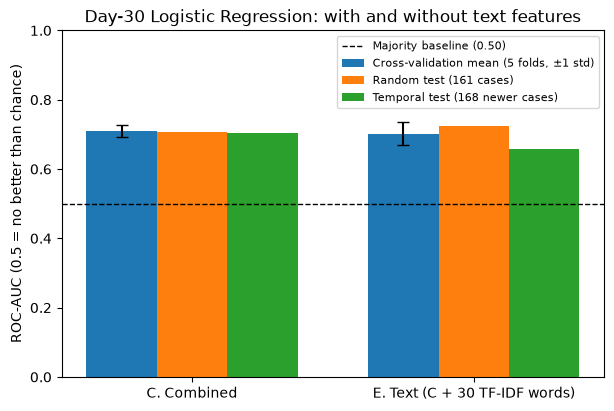

In [32]:
chart_rows = ["C. Combined", "E. Text"]
positions = [0, 1]
width = 0.25

plt.figure(figsize=(7, 4.5))
plt.bar([p - width for p in positions], comparison.loc[chart_rows, "CV ROC-AUC mean"], width,
        yerr=comparison.loc[chart_rows, "CV ROC-AUC std"], capsize=4, label="Cross-validation mean (5 folds, ±1 std)")
plt.bar(positions, comparison.loc[chart_rows, "Random ROC-AUC"], width, label="Random test (161 cases)")
plt.bar([p + width for p in positions], comparison.loc[chart_rows, "Temporal ROC-AUC"], width,
        label="Temporal test (168 newer cases)")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Majority baseline (0.50)")
plt.xticks(positions, ["C. Combined", "E. Text (C + 30 TF-IDF words)"])
plt.ylim(0, 1)
plt.ylabel("ROC-AUC (0.5 = no better than chance)")
plt.title("Day-30 Logistic Regression: with and without text features")
plt.legend(loc="upper right", fontsize=8)
plt.show()

## 15. Leakage Check

I change the activity code, the resource **and the English description** of every event after each case's day-30
cutoff to fake values (cohort and cutoffs fixed), and rebuild the case texts and the TF-IDF features with the same
fitted vectorizer. If the text features only use events up to day 30, nothing may change.

In [33]:
changed = df.copy()
after_day30 = changed["time:timestamp"] > changed["case:concept:name"].map(active["prediction_time"])
changed.loc[after_day30, "concept:name"] = "FAKE_ACTIVITY"
changed.loc[after_day30, "org:resource"] = "FAKE_RESOURCE"
changed.loc[after_day30, "activityNameEN"] = "fake future description"
changed_first30 = add_activity_groups(events_by_day30(changed, active))
all_ids = list(counts.index)

In [34]:
original_documents = case_documents(first30, all_ids)
changed_documents = case_documents(changed_first30, all_ids)

original_text = random_words.transform(original_documents).toarray()
changed_text = random_words.transform(changed_documents).toarray()

print("Events changed:", after_day30.sum())
print("Case texts unchanged:", changed_documents.equals(original_documents))
print("TF-IDF features unchanged:", (original_text == changed_text).all())
print("The word 'fake' appears in a day-30 text:", changed_documents.str.contains("fake").any())

Events changed: 26120
Case texts unchanged: True
TF-IDF features unchanged: True
The word 'fake' appears in a day-30 text: False


**What this check shows, and what it does not.** Three separate questions:

1. **Feature timing:** the text features use only descriptions of events timestamped on or before day 30. The check
   above tests this in code.
2. **Retrospective cohort selection:** a case is included only if its last recorded event is after day 30, which is
   only known afterwards. The check does not change this.
3. **Real-world knowledge of open cases:** a live system would need to know which cases are really still open at
   day 30. This log does not show that reliably.

A successful leakage check does **not** solve limitations 2 and 3.

## 16. Interpretation

**Text data quality.** No description is missing or empty. The log has 289 distinct descriptions for 398 activity codes:
377 codes always have the same description, 21 codes have more than one, and 91 descriptions are shared by more than
one code. So the descriptions are **fixed labels of the activity codes**, not free text, and they match the codes closely
but not one to one. By day 30, 163 distinct descriptions are recorded.

**Text features.** With the fixed settings, every training group (each fold, random and temporal) produced exactly
30 text features. Many of the 30 words appear in almost every case: on the random training cases, 19 of them appear in
more than 85% of the texts (for example *date*, *request* and *register* in 99.4%, 99.4% and 99.3%), so they can separate
cases only a little.

**C reproduces notebook 14 exactly** (0.710 / 0.708 / 0.705), so the comparison is fair.

**Did the text features improve cross-validation?** No. The mean cross-validation ROC-AUC is 0.702 for E and 0.710 for C,
and E varies more between the folds (standard deviation 0.033 vs 0.017). By the rule fixed in advance, **C stays the
preferred approach**.

**Test sets (not used for the choice).** The results go in different directions: E is higher on the random test (0.725
vs 0.708) but clearly lower on the temporal test (0.657 vs 0.705), where it also flags fewer cases (53 of 168) and finds
fewer long cases (recall 0.44 vs 0.50).

**Answer.** With these settings, the activity descriptions do **not** add useful information beyond the activity-code
features of approach C. This is understandable, because the descriptions are mostly labels of the same activity codes. This
is a valid negative result for the tested text features; it does not show that other text, such as free notes written by
staff, would be uninformative.

## 17. Limitations

- The random and temporal test cases were **already used** during exploratory modelling in notebooks 07–15, so they are
  **not** independent final validations. The temporal check is a chronological robustness check: 138 of its 168 test
  cases were training cases in the random split.
- The 63-day threshold is **exploratory**: it was chosen with all completed cases in `01_EDA.ipynb`.
- The cohort is retrospective.
- The descriptions are fixed labels of activity codes, not free text written by staff, so the text mostly repeats
  information that the activity codes already contain.
- Predictive relationships are **not causal explanations**; individual TF-IDF words or coefficients are not reasons why
  cases take longer.
- Only one fixed TF-IDF setting and Logistic Regression were tested.
- The data comes from **one Dutch municipality**, not from SPAR or Montenegro.